# Inception-V3: ajuste, ejecución definitiva y evaluación

Este notebook entrena y evalúa Inception-V3 con las funciones de `src/` (`train.py`, `tune.py`,
`final.py`, `results.py`, `evaluation.py`, `gradcam.py`, `interpret.py`, `verify_models.py`). El modelo se elige con la variable
`MODELO` de la sección 1; el resto del notebook es igual para todos los modelos (plantilla de
`08-mobilenetv2.ipynb`), con el mismo pipeline, espacio de búsqueda y presupuesto. Todos los
parámetros se leen de `configs/base.yaml` y `configs/<modelo>.yaml`. El ajuste usa
solo los pliegues de entrenamiento; test se evalúa únicamente en la ejecución definitiva. Si
faltan resultados, cada sección muestra un aviso y el notebook continúa.

## 1. Configuración

Modelo y flags de reejecución. Con un flag en `False`, la sección correspondiente carga los
resultados guardados y, si no existen, muestra un aviso sin ejecutar nada. Con `True`, llama a
`src.tune` o `src.final`, que reutilizan las corridas terminadas y ejecutan las pendientes.

In [1]:
MODELO = "inceptionv3"
RERUN_AJUSTE = False
RERUN_FINAL = False

In [2]:
import pandas as pd

from src import data, evaluation, final, gradcam, interpret, results
from src.report import show
from src.train import build_model, configure_runtime, load_model_config
from src.tune import run_tuning
from src.utils import environment_info, set_seed
from src.verify_models import verify_model

Carga de las configuraciones, memory growth en la GPU, política de precisión
(`train.mixed_precision`) y semilla (`seed` de `base.yaml`).

In [3]:
cfg = data.load_config()
cfg_modelo = load_model_config(MODELO)
configure_runtime(cfg)
set_seed(cfg["seed"], deterministic=cfg["train"]["deterministic"])
rutas = cfg["paths"]
cfg_train = cfg["train"]
cfg_eval = cfg["evaluation"]
ALPHA = cfg["benchmark"]["alpha"]

pd.Series({
    "modelo": cfg_modelo["name"],
    "implementación": cfg_modelo.get("keras_application") or f"keras_hub: {cfg_modelo.get('keras_hub_preset')}",
    "pesos": cfg_modelo["weights"],
    "entrada": f"{cfg_modelo['input_size']} x {cfg_modelo['input_size']}",
    "saliencia": cfg_modelo.get("saliency"),
    "capa de Grad-CAM": cfg_modelo.get("gradcam_layer"),
    "clases": ", ".join(data.class_names(cfg)),
    "batch_size": cfg_train["batch_size"],
    "mixed_precision": cfg_train["mixed_precision"],
    "deterministic": cfg_train["deterministic"],
    "épocas fase A": cfg_train["warmup"]["epochs"],
    "épocas máximas fase B": cfg_train["finetune"]["max_epochs"],
    "semilla del notebook": cfg["seed"],
}, name="valor").to_frame()

2026-11-28 05:34:35.985948: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


,valor
modelo,inceptionv3
implementación,InceptionV3
pesos,imagenet
entrada,224 x 224
saliencia,gradcam
capa de Grad-CAM,mixed10
clases,"akiec, bcc, bkl, df, mel, nv, vasc"
batch_size,32
mixed_precision,True
deterministic,False


GPU detectada y versiones de Python, TensorFlow, Keras, CUDA y cuDNN (estas dos, las de
compilación de TensorFlow).

In [4]:
results.environment_table(environment_info())

,valor
python,3.11.18
tensorflow,2.20.0
keras,3.15.1
cuda,12.5.1
cudnn,9
platform,Linux-7.2.11-300.fc45.x86_64-x86_64-with-glibc...
gpu,ninguna


## 2. Modelo

Arquitectura: entrada en [0, 255], preprocesamiento de la aplicación dentro del modelo, backbone
anidado con `training=False` y cabeza nativa de Inception-V3: `GlobalAveragePooling2D`, `Dropout` y `Dense` softmax en float32 (la capa de 1000 clases sustituida por 7). El backbone son los módulos de `InceptionV3(include_top=False)` a 224 × 224 en lugar de la resolución nativa de 299 × 299; el último módulo, `mixed10`, produce un mapa de 5 × 5. El dropout es el del YAML, o 0.0 si aún es null (no cambia el número de parámetros).

In [5]:
modelo = build_model(cfg, MODELO)
modelo.summary()

Model: "inceptionv3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Lambda)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ backbone (Functional)           │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 7)              │        14,343 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,817,127 (83.23 MB)

 Trainable params: 14,343 (56.03 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

Parámetros entrenables y no entrenables con el backbone congelado (fase A) y descongelado (fase B).
Los no entrenables restantes en la fase B son las medias y varianzas móviles de BatchNormalization
(ConvNeXt y ViT usan normalización de capa y no tienen).

In [6]:
results.model_parameter_table(modelo)

,trainable,non_trainable,total
backbone congelado,14343,21802784,21817127
backbone descongelado,21782695,34432,21817127


Verificación de la arquitectura con `src.verify_models`: número total de parámetros frente a
`expected_params` de `configs/<modelo>.yaml` (construido sin pesos) y estructura que asume el
pipeline (capa `preprocess`, backbone anidado y salida de 7 clases en float32).

In [7]:
verify_model(cfg, MODELO)

{'modelo': 'inceptionv3',
 'parametros_totales': 21817127,
 'esperados': 21817127,
 'entrenables_fase_A': 14343,
 'entrenables_fase_B': 21782695,
 'no_entrenables_fase_B': 34432,
 'capa preprocess': True,
 'backbone anidado': True,
 'salida float32': True,
 'salida de 7 clases': True,
 'entrada 224': True,
 'parámetros esperados': True,
 'ok': True}

## 3. Ajuste de hiperparámetros

Búsqueda aleatoria de `train.tuning`: `n_trials` configuraciones muestreadas con `sampler_seed`
(las mismas para los tres modelos), una corrida por configuración con `seed` y `val_fold` fijos y la
fase B limitada a `tuning.max_epochs`.

In [8]:
pd.DataFrame(cfg_train["tuning"]["space"]).T

,type,low,high,values
learning_rate,loguniform,0.00001,0.001,NaN
weight_decay,loguniform,0.000001,0.001,NaN
dropout,choice,NaN,NaN,"[0.0, 0.2, 0.4]"


### 3.1 Ejecución

Carga `outputs/tuning/<modelo>/trials.csv` si existe; con `RERUN_AJUSTE = True`, llama a
`run_tuning`. Si el ajuste se interrumpió, el archivo contiene solo los ensayos terminados.

In [9]:
dir_ajuste = rutas["tuning_dir"] / MODELO
ensayos, origen = results.load_or_run(
    dir_ajuste / "trials.csv", lambda: run_tuning(cfg, MODELO), RERUN_AJUSTE,
    missing_message=f"no hay ensayos de ajuste de {MODELO}; ejecuta `python -m src.tune --model {MODELO}` "
                    "o pon RERUN_AJUSTE = True.")
results.load_status(dir_ajuste / "trials.csv", ensayos, origen, "ensayos")

,valor
archivo,outputs/tuning/inceptionv3/trials.csv
estado,cargado
ensayos,6


### 3.2 Resultados

Configuraciones ordenadas por exactitud balanceada de validación (`best_epoch` es la época de la
fase B cuyos pesos se restauraron).

In [10]:
results.tuning_table(ensayos)

,trial,learning_rate,weight_decay,dropout,val_balanced_accuracy,best_epoch,epochs_warmup,epochs_finetune,train_time_s,run_dir,excluded,excluded_reason
0,2,0.000381,0.000519,0.4,0.761058,12,5,15,588.781372,outputs/runs/inceptionv3/tuning_t02/s0_f0,False,NaN
1,5,0.000320,0.000035,0.2,0.747667,12,5,15,578.477669,outputs/runs/inceptionv3/tuning_t05/s0_f0,False,NaN
2,3,0.000202,0.000008,0.0,0.736611,7,5,12,518.390620,outputs/runs/inceptionv3/tuning_t03/s0_f0,False,NaN
3,1,0.000055,0.000012,0.2,0.689264,9,5,14,543.212774,outputs/runs/inceptionv3/tuning_t01/s0_f0,False,NaN
4,0,0.000023,0.000083,0.2,0.647234,6,5,11,506.249127,outputs/runs/inceptionv3/tuning_t00/s0_f0,False,NaN
5,4,0.000859,0.000575,0.0,0.608672,12,5,15,590.657430,outputs/runs/inceptionv3/tuning_t04/s0_f0,False,NaN


Mejor configuración según `best.json` (se escribe al terminar todos los ensayos).

In [11]:
mejor = results.load_json_or_missing(
    dir_ajuste / "best.json",
    f"no existe outputs/tuning/{MODELO}/best.json; se escribe al terminar `python -m src.tune --model {MODELO}`.")
results.best_table(mejor)

,valor
ensayo,2.000000
learning_rate,0.000381
weight_decay,0.000519
dropout,0.400000
val_balanced_accuracy,0.761058
best_epoch,12.000000


Exactitud balanceada de validación frente a cada hiperparámetro (eje logarítmico para los de
distribución loguniforme). El número junto a cada punto es el índice del ensayo; el círculo rojo
marca el mejor.

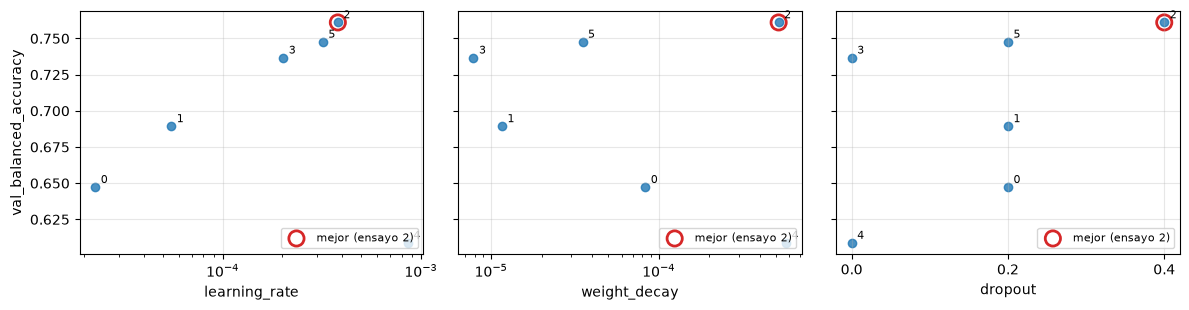

In [12]:
show(results.plot_metric_vs_hparams(ensayos, cfg_train["tuning"]["space"], best_trial=results.best_trial(mejor)))

### 3.3 Hiperparámetros seleccionados

Valores de la sección `hyperparameters` de `configs/<modelo>.yaml` frente a `best.json`. Se emite
un aviso si alguno es null o difiere.

In [13]:
results.compare_hparams(cfg_modelo, mejor)

/tmp/ipykernel_228667/1570348254.py:1: UserWarning: configs/inceptionv3.yaml: learning_rate (null en el YAML), weight_decay (null en el YAML), dropout (null en el YAML)
  results.compare_hparams(cfg_modelo, mejor)


,yaml,best.json,estado
learning_rate,None,0.000381,null en el YAML
weight_decay,None,0.000519,null en el YAML
dropout,None,0.4,null en el YAML


## 4. Estudio piloto

Estudio piloto omitido (desviación D2, capítulo 7).

## 5. Ejecución definitiva

Validación cruzada repetida: producto `final.seeds` x `final.folds` de `base.yaml`, con los
hiperparámetros del YAML del modelo. Cada corrida evalúa validación y test, calcula las métricas de
su train sin aumento ni dropout y guarda sus pesos. El número de semillas se fijó por cómputo en `preregistro.md`
(desviación D3, capítulo 7).

In [14]:
final.config_table(cfg)

,valor
etiqueta,final
semillas,[0]
pliegues,"[0, 1, 2, 3, 4]"
corridas,5
evaluación de test,True
métricas de train sin aumento,True
pesos guardados,True


### 5.1 Ejecución

Con `RERUN_FINAL = False`, carga las corridas definitivas terminadas sin ejecutar nada; con `True`,
llama a `run_final`, que reutiliza las terminadas y ejecuta las pendientes (equivale a
`python -m src.final --model <modelo>`). Resumen y estado de cada corrida prevista.

In [15]:
corridas, estado = final.load_or_run_final(cfg, MODELO, rerun=RERUN_FINAL)
show(results.runs_summary(corridas))
final.status_summary(estado)

,valor
corridas terminadas,5
corridas,"s0_f0, s0_f1, s0_f2, s0_f3, s0_f4"


,corridas
previstas,5
terminadas,5
pendientes,0


In [16]:
estado

,seed,val_fold,estado,run_dir
0,0,0,terminada,outputs/runs/inceptionv3/final/s0_f0
1,0,1,terminada,outputs/runs/inceptionv3/final/s0_f1
2,0,2,terminada,outputs/runs/inceptionv3/final/s0_f2
3,0,3,terminada,outputs/runs/inceptionv3/final/s0_f3
4,0,4,terminada,outputs/runs/inceptionv3/final/s0_f4


### 5.2 Resultados por corrida

Métricas globales de validación por corrida con los pesos restaurados. Al final, media, desviación
estándar (ddof = 1) e intervalo de confianza al 95 % de la media por t de Student
(`ci95_low`, `ci95_high`).

In [17]:
results.add_summary_rows(results.run_metrics_table(corridas, split="val"), alpha=ALPHA)

,balanced_accuracy,accuracy,f1_macro,f1_weighted,auc_roc_macro_ovr,auc_pr_macro,mcc,ece
s0_f0,0.670902,0.740827,0.607006,0.761697,0.941055,0.675369,0.569215,0.019304
s0_f1,0.749405,0.790332,0.672015,0.796953,0.953430,0.750651,0.628268,0.052433
s0_f2,0.763933,0.680256,0.544286,0.710589,0.931217,0.720556,0.532512,0.070218
s0_f3,0.651566,0.717531,0.586054,0.740299,0.932678,0.680326,0.543925,0.051255
s0_f4,0.735937,0.695804,0.632003,0.729887,0.950834,0.742686,0.556212,0.141702
mean,0.714348,0.724950,0.608273,0.747885,0.941843,0.713918,0.566026,0.066982
std,0.049957,0.043096,0.047999,0.033056,0.010157,0.034769,0.037391,0.045623
ci95_low,0.652319,0.671440,0.548674,0.706840,0.929232,0.670747,0.519599,0.010335
ci95_high,0.776378,0.778460,0.667872,0.788930,0.954454,0.757089,0.612453,0.123630


Las mismas métricas sobre test.

In [18]:
results.add_summary_rows(results.run_metrics_table(corridas, split="test"), alpha=ALPHA)

,balanced_accuracy,accuracy,f1_macro,f1_weighted,auc_roc_macro_ovr,auc_pr_macro,mcc,ece
s0_f0,0.595735,0.721873,0.560989,0.742000,0.940000,0.613472,0.534371,0.031866
s0_f1,0.674591,0.791055,0.626744,0.793726,0.934295,0.671810,0.611530,0.041890
s0_f2,0.651706,0.646401,0.485877,0.679358,0.912268,0.589735,0.475622,0.092162
s0_f3,0.617604,0.712788,0.561066,0.733846,0.926030,0.626743,0.535196,0.031060
s0_f4,0.651184,0.680643,0.586339,0.714746,0.931853,0.657925,0.527243,0.148545
mean,0.638164,0.710552,0.564203,0.732735,0.928889,0.631937,0.536792,0.069105
std,0.031236,0.053907,0.051372,0.041772,0.010558,0.033220,0.048547,0.051032
ci95_low,0.599380,0.643618,0.500416,0.680868,0.915779,0.590689,0.476514,0.005740
ci95_high,0.676949,0.777486,0.627990,0.784602,0.941999,0.673185,0.597071,0.132469


Precisión, sensibilidad y F1 por clase en test: media y desviación estándar entre corridas.

In [19]:
por_clase_test = results.per_class_table(corridas, split="test")
results.per_class_summary(por_clase_test)

precision              recall                  f1          
           mean       std      mean       std      mean       std
class                                                            
akiec  0.459262  0.097457  0.460870  0.140382  0.444397  0.094060
bcc    0.644062  0.109349  0.654054  0.194801  0.621157  0.082680
bkl    0.515958  0.065899  0.611465  0.033704  0.557299  0.038190
df     0.285838  0.087825  0.458824  0.076696  0.343984  0.078084
mel    0.371477  0.064500  0.623899  0.132330  0.454449  0.035288
nv     0.944122  0.014873  0.758038  0.091458  0.837924  0.049755
vasc   0.591749  0.197188  0.900000  0.093541  0.690211  0.142236

Matriz de confusión de test acumulada sobre las corridas y normalizada por fila.

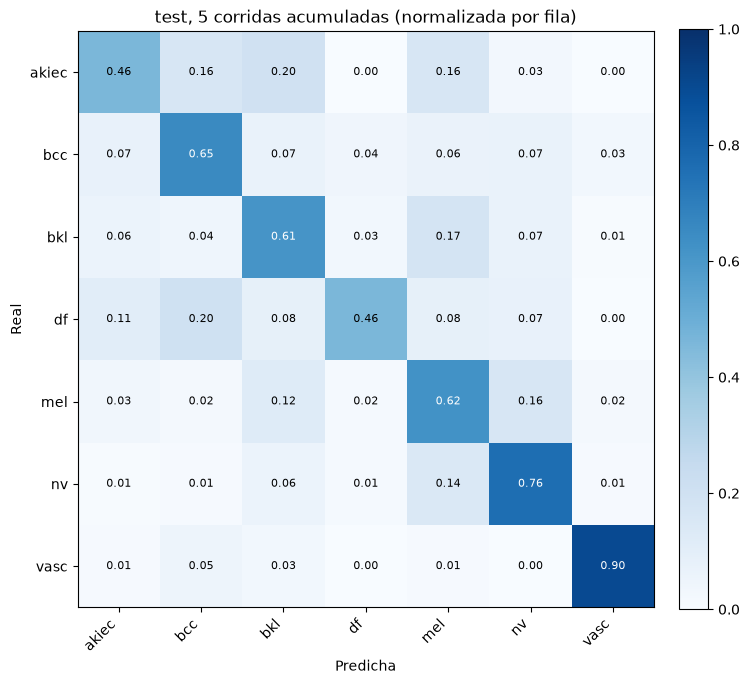

In [20]:
show(results.plot_pooled_confusion(corridas, split="test"))

Costo computacional por corrida (con la inferencia por imagen en validación, test y train) y épocas
de la fase B ejecutadas y restauradas.

In [21]:
results.add_mean_std(results.cost_table(corridas))

,warmup_s,finetune_s,total_s,epochs_warmup,epochs_finetune,finetune_s_per_epoch,inference_ms_per_image_val,inference_ms_per_image_test,inference_ms_per_image_train,trainable_params_finetune,non_trainable_params_finetune,gpu
s0_f0,86.395405,478.403309,564.798714,5.0,14.00000,34.171665,0.967383,7.764159,1.470721,21782695.0,34432.0,NVIDIA GeForce RTX 3050 6GB Laptop GPU
s0_f1,75.756694,675.695771,751.452464,5.0,20.00000,33.784789,0.972370,3.462217,1.466452,21782695.0,34432.0,NVIDIA GeForce RTX 3050 6GB Laptop GPU
s0_f2,68.525981,464.793997,533.319978,5.0,13.00000,35.753384,0.966266,3.361636,1.461212,21782695.0,34432.0,NVIDIA GeForce RTX 3050 6GB Laptop GPU
s0_f3,68.397288,344.101497,412.498785,5.0,9.00000,38.233500,0.974196,3.460718,1.515110,21782695.0,34432.0,NVIDIA GeForce RTX 3050 6GB Laptop GPU
s0_f4,73.429925,619.238948,692.668873,5.0,18.00000,34.402164,0.969964,3.568101,0.977000,21782695.0,34432.0,NVIDIA GeForce RTX 3050 6GB Laptop GPU
mean,74.501059,516.446704,590.947763,5.0,14.80000,35.269100,0.970036,4.323366,1.378099,21782695.0,34432.0,NaN
std,7.368124,132.046093,134.124677,0.0,4.32435,1.815304,0.003317,1.924847,0.225247,0.0,0.0,NaN


In [22]:
results.restored_epochs_table(corridas)

,finetune_run,finetune_best
s0_f0,14.00000,9.00000
s0_f1,20.00000,15.00000
s0_f2,13.00000,8.00000
s0_f3,9.00000,4.00000
s0_f4,18.00000,13.00000
mean,14.80000,9.80000
std,4.32435,4.32435


### 5.3 Curvas de entrenamiento

Curvas de todas las corridas definitivas superpuestas: una línea fina por corrida y la media por
época global en negro (con las corridas que llegan a esa época). La línea discontinua marca el paso
de la fase A a la B.

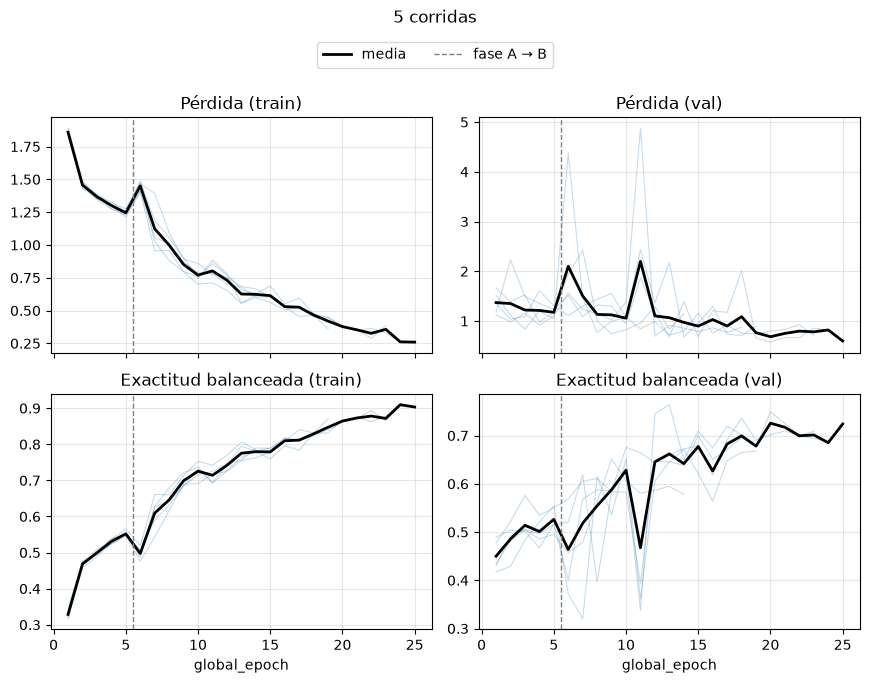

In [23]:
show(results.plot_training_curves_overlay(results.load_histories(corridas)))

## 6. Evaluación

Análisis de las predicciones guardadas de las corridas definitivas sobre `evaluation.split` (test),
con los parámetros de la sección `evaluation` de `base.yaml`. Carga de las probabilidades de todas
las corridas y de los metadatos.

In [24]:
pred_test = evaluation.load_predictions(corridas, cfg_eval["split"])
metadatos = evaluation.load_metadata_or_missing(cfg)
evaluation.predictions_summary(pred_test)

,valor
corridas,5
imagenes,1431
predicciones,7155


### 6.1 Robustez por subgrupos

Exactitud balanceada, exactitud y F1 macro de test por fuente (`dataset`), método diagnóstico
(`dx_type`) y localización: media y desviación estándar entre corridas e imágenes por corrida. F1
macro se promedia sobre las clases presentes en cada subgrupo. `pocas_imagenes` marca los subgrupos
con menos de `subgroup_min_n` imágenes.

In [25]:
subgrupos = evaluation.subgroup_report(pred_test, metadatos, cfg_eval["subgroups"],
                                       cfg_eval["subgroup_metrics"], cfg_eval["subgroup_min_n"])
show(subgrupos)

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pr

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:614: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2

/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/var/home/luencaro/Programing/College/2026-30/Deep Learning/skin-lesion-dl/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:614: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the c

**dataset**

,n_imagenes,corridas,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,pocas_imagenes
dataset,,,,,,,,,
vidir_molemax,567.0,5,0.752990,0.048806,0.934039,0.039938,0.645424,0.076708,False
vidir_modern,455.0,5,0.555198,0.023849,0.581538,0.080492,0.489256,0.052472,False
rosendahl,330.0,5,0.518099,0.056069,0.537576,0.057838,0.496787,0.051880,False
vienna_dias,79.0,5,0.630714,0.086625,0.572152,0.159464,0.514735,0.025700,False


**dx_type**

,n_imagenes,corridas,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,pocas_imagenes
dx_type,,,,,,,,,
histo,776.0,5,0.564089,0.055740,0.548711,0.067130,0.491635,0.045833,False
follow_up,530.0,5,0.947547,0.045954,0.947547,0.045954,0.972598,0.024835,False
consensus,118.0,5,0.749442,0.044698,0.694915,0.079046,0.784532,0.042545,False
confocal,7.0,5,0.971429,0.063888,0.971429,0.063888,0.984615,0.034401,True


**localization**

,n_imagenes,corridas,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,pocas_imagenes
localization,,,,,,,,,
back,323.0,5,0.704621,0.079736,0.647678,0.059769,0.581865,0.056050,False
lower extremity,310.0,5,0.621774,0.058040,0.737419,0.064258,0.549370,0.076947,False
trunk,197.0,5,0.672937,0.106293,0.843655,0.052923,0.615108,0.095139,False
upper extremity,156.0,5,0.630955,0.079042,0.689744,0.040694,0.592555,0.052495,False
abdomen,147.0,5,0.697247,0.105901,0.798639,0.058440,0.605031,0.053191,False
face,84.0,5,0.519319,0.052196,0.597619,0.042425,0.519731,0.065785,False
foot,59.0,5,0.492714,0.098224,0.722034,0.073490,0.487680,0.056992,False
chest,52.0,5,0.637143,0.100727,0.546154,0.039878,0.548709,0.085213,False
unknown,34.0,5,0.525000,0.118276,0.635294,0.115045,0.581320,0.123465,False


Exactitud balanceada por subgrupo con la desviación estándar entre corridas como barra de error;
en gris, los subgrupos con pocas imágenes.

**dataset**

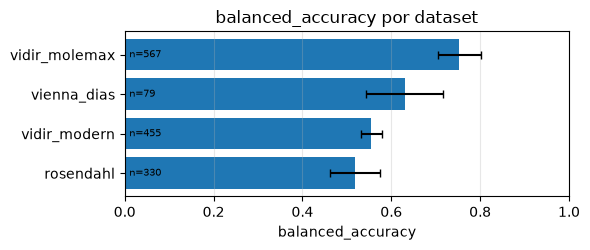

**dx_type**

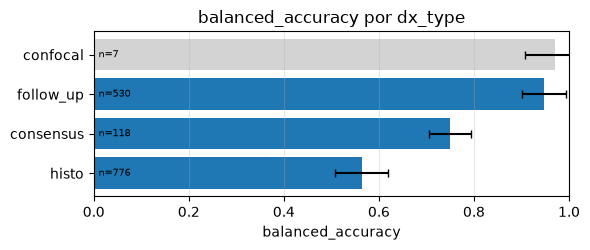

**localization**

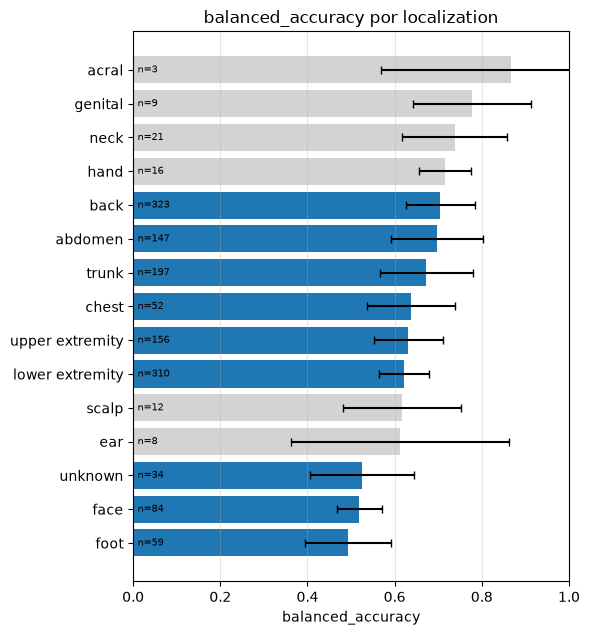

In [26]:
show(evaluation.plot_subgroup_report(subgrupos, "balanced_accuracy"))

### 6.2 Diagnóstico de sobreajuste

Métricas en el train de cada corrida (sin aumento de datos y sin dropout), en validación y en test,
y las brechas train - val y val - test: media y desviación estándar entre corridas.

In [27]:
sobreajuste = evaluation.overfitting_table(corridas, cfg_eval["overfitting_metrics"])
evaluation.overfitting_summary(sobreajuste, cfg_eval["overfitting_metrics"])

,train_mean,train_std,val_mean,val_std,test_mean,test_std,gap_train_val_mean,gap_train_val_std,gap_val_test_mean,gap_val_test_std
balanced_accuracy,0.816180,0.064822,0.714348,0.049957,0.638164,0.031236,0.101832,0.047148,0.076184,0.028099
accuracy,0.764475,0.066248,0.724950,0.043096,0.710552,0.053907,0.039525,0.027243,0.014398,0.013433
f1_macro,0.697855,0.100806,0.608273,0.047999,0.564203,0.051372,0.089582,0.054383,0.044070,0.012016
cross_entropy,0.602366,0.177608,0.732626,0.123244,0.767087,0.129533,-0.130260,0.071407,-0.034462,0.016472


Exactitud balanceada en train, validación y test por corrida y su media.

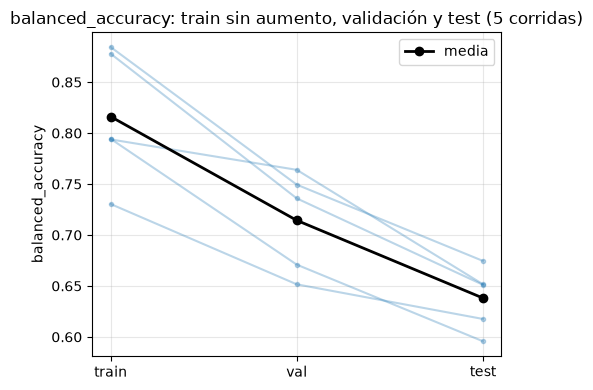

In [28]:
show(evaluation.plot_overfitting(sobreajuste, "balanced_accuracy"))

Valores por corrida.

In [29]:
sobreajuste

,balanced_accuracy_train,balanced_accuracy_val,balanced_accuracy_test,balanced_accuracy_gap_train_val,balanced_accuracy_gap_val_test,accuracy_train,accuracy_val,accuracy_test,accuracy_gap_train_val,accuracy_gap_val_test,f1_macro_train,f1_macro_val,f1_macro_test,f1_macro_gap_train_val,f1_macro_gap_val_test,cross_entropy_train,cross_entropy_val,cross_entropy_test,cross_entropy_gap_train_val,cross_entropy_gap_val_test
s0_f0,0.794366,0.670902,0.595735,0.123464,0.075167,0.782001,0.740827,0.721873,0.041174,0.018954,0.711591,0.607006,0.560989,0.104585,0.046017,0.557081,0.677203,0.697601,-0.120123,-0.020397
s0_f1,0.884438,0.749405,0.674591,0.135033,0.074813,0.865589,0.790332,0.791055,0.075257,-0.000723,0.813240,0.672015,0.626744,0.141225,0.045271,0.364429,0.575686,0.603325,-0.211257,-0.027639
s0_f2,0.793790,0.763933,0.651706,0.029858,0.112227,0.686035,0.680256,0.646401,0.005778,0.033855,0.564455,0.544286,0.485877,0.020169,0.058409,0.842057,0.912941,0.949335,-0.070883,-0.036394
s0_f3,0.730389,0.651566,0.617604,0.078823,0.033962,0.738751,0.717531,0.712788,0.021220,0.004742,0.631655,0.586054,0.561066,0.045600,0.024989,0.691639,0.744948,0.770755,-0.053310,-0.025807
s0_f4,0.877916,0.735937,0.651184,0.141979,0.084753,0.750000,0.695804,0.680643,0.054196,0.015161,0.768333,0.632003,0.586339,0.136330,0.045664,0.556624,0.752350,0.814422,-0.195725,-0.062072
mean,0.816180,0.714348,0.638164,0.101832,0.076184,0.764475,0.724950,0.710552,0.039525,0.014398,0.697855,0.608273,0.564203,0.089582,0.044070,0.602366,0.732626,0.767087,-0.130260,-0.034462
std,0.064822,0.049957,0.031236,0.047148,0.028099,0.066248,0.043096,0.053907,0.027243,0.013433,0.100806,0.047999,0.051372,0.054383,0.012016,0.177608,0.123244,0.129533,0.071407,0.016472


### 6.3 Análisis de errores

Sensibilidad (`recall`) y precisión por clase en test: media y desviación estándar entre corridas.

In [30]:
results.per_class_summary(por_clase_test, cols=("recall", "precision"))

recall           precision          
           mean       std      mean       std
class                                        
akiec  0.460870  0.140382  0.459262  0.097457
bcc    0.654054  0.194801  0.644062  0.109349
bkl    0.611465  0.033704  0.515958  0.065899
df     0.458824  0.076696  0.285838  0.087825
mel    0.623899  0.132330  0.371477  0.064500
nv     0.758038  0.091458  0.944122  0.014873
vasc   0.900000  0.093541  0.591749  0.197188

Pares de clases más confundidos en la matriz de test acumulada: conteo, porcentaje sobre las
imágenes de la clase real y sobre el total de errores.

In [31]:
evaluation.confused_pairs_from_runs(corridas, cfg_eval["split"], cfg_eval["top_confused_pairs"])

,real,predicha,conteo,pct_de_la_clase_real,pct_de_los_errores
0,nv,mel,691,14.425887,33.365524
1,nv,bkl,283,5.908142,13.664896
2,bkl,mel,137,17.452229,6.615162
3,mel,nv,129,16.226415,6.228875
4,mel,bkl,99,12.452830,4.780299
5,nv,df,61,1.273486,2.945437
6,bkl,nv,55,7.006369,2.655722
7,nv,vasc,52,1.085595,2.510864
8,bkl,akiec,48,6.114650,2.317721
9,nv,bcc,47,0.981211,2.269435


Tasa de error en las imágenes marcadas en `data/atipicos_imagenes.csv` frente a las no marcadas,
por tipo de marca (Mahalanobis robusta, al menos `univariate_min_marks` marcas univariadas, o
cualquiera). El archivo cubre solo las imágenes de train, así que se usan las predicciones de
validación de cada corrida (fuera de pliegue).

In [32]:
pred_val = evaluation.load_predictions(corridas, cfg_eval["outliers"]["split"])
evaluation.outlier_error_rates(pred_val, evaluation.outlier_flags(cfg))

,n_marcadas,error_marcadas_mean,error_marcadas_std,n_no_marcadas,error_no_marcadas_mean,error_no_marcadas_std,diferencia
marca,,,,,,,
mahalanobis,662.0,0.358002,0.061902,1055.0,0.222943,0.035752,0.135059
univariante,788.0,0.331524,0.047744,928.0,0.226684,0.042709,0.104841
cualquiera,933.0,0.331485,0.050309,783.0,0.207825,0.039047,0.123660


### 6.4 Casos difíciles

Imágenes de test que fallan en más de `hard_cases.min_error_frac` de las corridas, y su número por
clase real.

In [33]:
cfg_dificiles = cfg_eval["hard_cases"]
frecuencia = evaluation.image_error_frequency(pred_test)
evaluation.hard_cases_by_class(frecuencia, cfg_dificiles["min_error_frac"])

,imagenes,dificiles,pct_dificiles
label,,,
akiec,46,25,54.347826
bcc,74,23,31.081081
bkl,157,55,35.031847
df,17,8,47.058824
mel,159,56,35.220126
nv,958,209,21.816284
vasc,20,1,5.000000


In [34]:
dificiles = evaluation.hard_cases(frecuencia, cfg_dificiles["min_error_frac"])
dificiles

,label,corridas,errores,p_real_media,frac_error,pred_erronea_frecuente
image_id,,,,,,
ISIC_0024539,akiec,5,5,0.010168,1.0,bkl
ISIC_0024684,nv,5,5,0.010600,1.0,bkl
ISIC_0034169,df,5,5,0.014287,1.0,bcc
ISIC_0032075,nv,5,5,0.017557,1.0,vasc
ISIC_0026014,akiec,5,5,0.020088,1.0,mel
...,...,...,...,...,...,...
ISIC_0033607,mel,5,3,0.530276,0.6,nv
ISIC_0029027,nv,5,3,0.542143,0.6,mel
ISIC_0027711,nv,5,3,0.564729,0.6,mel


Cuadrícula de los casos difíciles con image_id, clase real, predicción errónea más frecuente y
fracción de corridas con error.

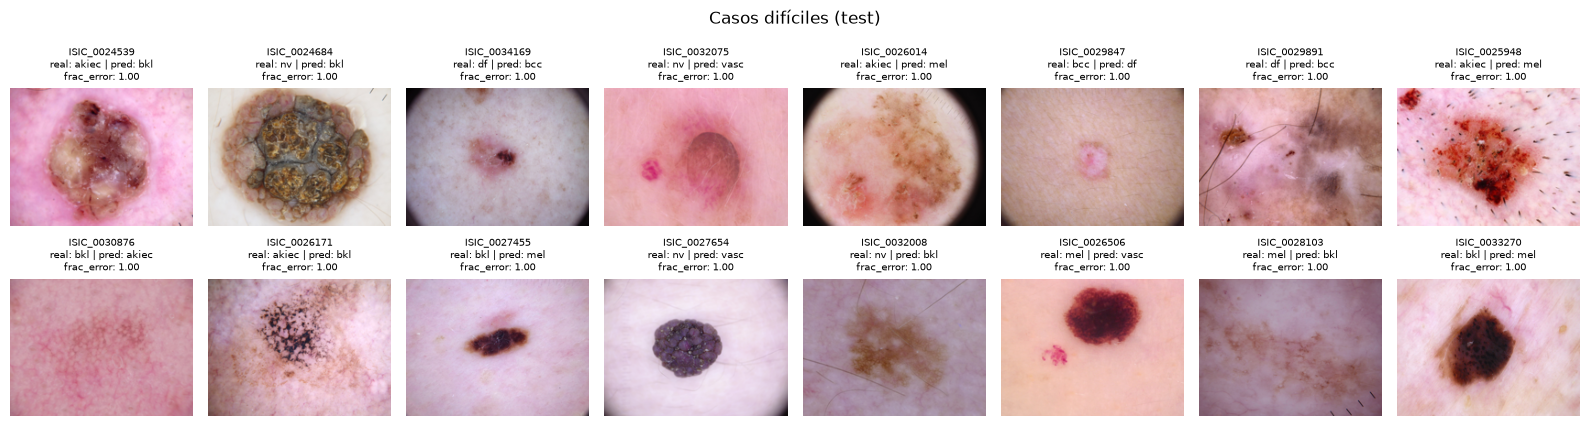

In [35]:
show(evaluation.plot_case_grid(cfg, dificiles, "pred_erronea_frecuente", "frac_error",
                               n=cfg_dificiles["grid_n"], ncols=cfg_dificiles["grid_ncols"],
                               title="Casos difíciles (test)"))

Errores con mayor confianza: una fila por imagen, con la corrida en que la probabilidad de la clase
predicha fue mayor.

In [36]:
errores_confiados = evaluation.confident_errors(pred_test, cfg_dificiles["grid_n"])
errores_confiados

,image_id,run,label,pred,confidence
0,ISIC_0026506,s0_f1,mel,vasc,1.000000
1,ISIC_0032075,s0_f1,nv,vasc,1.000000
2,ISIC_0029847,s0_f2,bcc,df,0.999999
3,ISIC_0031112,s0_f2,nv,df,0.999990
4,ISIC_0024539,s0_f4,akiec,bkl,0.999976
5,ISIC_0024684,s0_f4,nv,bkl,0.999846
6,ISIC_0027000,s0_f2,nv,df,0.999244
7,ISIC_0029362,s0_f1,akiec,bcc,0.999242
8,ISIC_0028132,s0_f1,akiec,bcc,0.999181
9,ISIC_0024748,s0_f2,bkl,vasc,0.998964


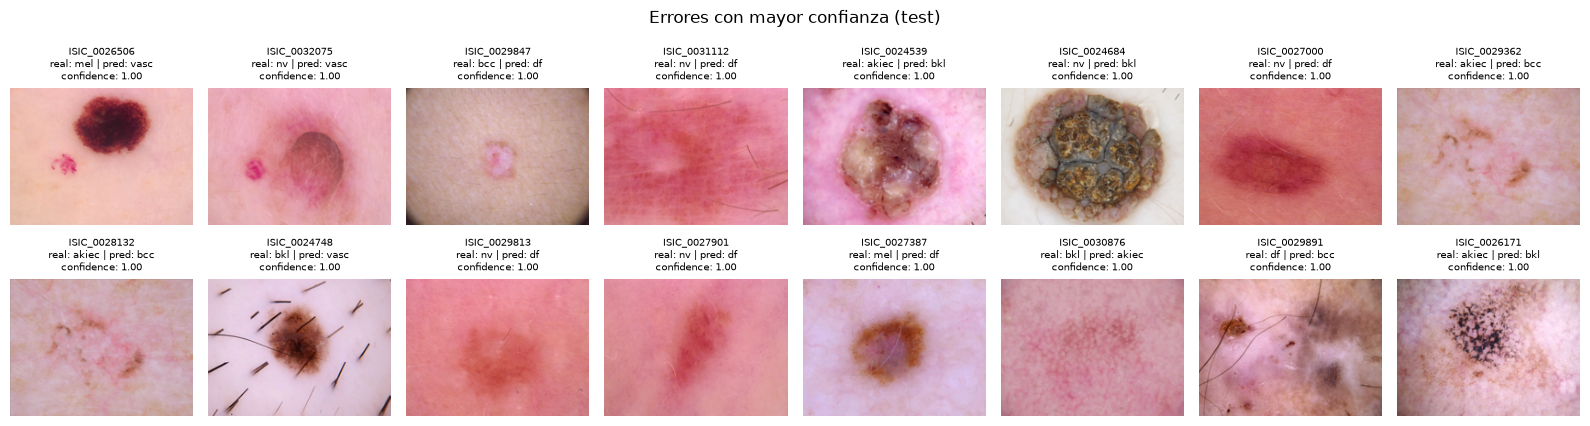

In [37]:
show(evaluation.plot_case_grid(cfg, errores_confiados, "pred", "confidence",
                               n=cfg_dificiles["grid_n"], ncols=cfg_dificiles["grid_ncols"],
                               title="Errores con mayor confianza (test)"))

### 6.5 Calibración

ECE de cada corrida en test (intervalos de igual ancho en la confianza, como `train.ece_bins`), con
la confianza media y la exactitud.

In [38]:
evaluation.calibration_by_run(pred_test, cfg_eval["calibration_bins"])

,ece,confianza_media,exactitud
s0_f0,0.031866,0.743022,0.721873
s0_f1,0.041890,0.822372,0.791055
s0_f2,0.092162,0.724296,0.646401
s0_f3,0.031060,0.687500,0.712788
s0_f4,0.148545,0.828125,0.680643
mean,0.069105,0.761063,0.710552
std,0.051032,0.061938,0.053907


Diagrama de fiabilidad: exactitud frente a confianza media por intervalo, una línea por corrida y
una con todas las corridas juntas; debajo, el histograma de confianzas.

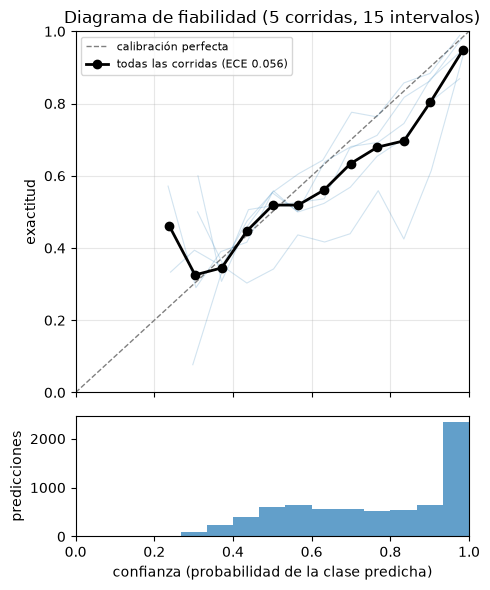

In [39]:
show(evaluation.plot_reliability(pred_test, cfg_eval["calibration_bins"]))

Valores por intervalo con todas las corridas juntas.

In [40]:
evaluation.pooled_reliability(pred_test, cfg_eval["calibration_bins"])

,desde,hasta,n,confianza_media,exactitud,brecha
0,0.000000,0.066667,0,NaN,NaN,NaN
1,0.066667,0.133333,0,NaN,NaN,NaN
2,0.133333,0.200000,0,NaN,NaN,NaN
3,0.200000,0.266667,13,0.237945,0.461538,0.223594
4,0.266667,0.333333,86,0.303605,0.325581,0.021977
5,0.333333,0.400000,232,0.371024,0.344828,0.026197
6,0.400000,0.466667,404,0.436093,0.448020,0.011927
7,0.466667,0.533333,605,0.501192,0.519008,0.017817
8,0.533333,0.600000,636,0.565672,0.518868,0.046804
9,0.600000,0.666667,562,0.631297,0.560498,0.070799


### 6.6 Mapas de saliencia

Grad-CAM respecto de la clase predicha sobre `gradcam_layer` para las CNN, y attention rollout del
token de clase para ViT (`saliency` del YAML del modelo), con los pesos de la corrida definitiva
`evaluation.gradcam.run`. Muestra fija de test: por clase, `per_class_correct` aciertos y
`per_class_wrong` errores, elegidos con `sample_seed`.

In [41]:
cfg_gradcam = cfg_eval["gradcam"]
corrida_gradcam = gradcam.gradcam_run_dir(cfg, MODELO)
muestra = gradcam.sample_images(corrida_gradcam, cfg_gradcam["per_class_correct"],
                                cfg_gradcam["per_class_wrong"], cfg_gradcam["sample_seed"])
muestra

,image_id,label,pred,resultado,confidence
0,ISIC_0026203,akiec,akiec,acierto,0.519332
1,ISIC_0031198,akiec,akiec,acierto,0.850693
2,ISIC_0026626,akiec,bkl,error,0.589168
3,ISIC_0028372,akiec,bkl,error,0.577999
4,ISIC_0024984,bcc,bcc,acierto,0.743586
5,ISIC_0028556,bcc,bcc,acierto,0.912699
6,ISIC_0027759,bcc,nv,error,0.562055
7,ISIC_0031378,bcc,bkl,error,0.381970
8,ISIC_0031542,bkl,bkl,acierto,0.729906
9,ISIC_0033079,bkl,bkl,acierto,0.459368


Cada par de filas muestra la imagen redimensionada como en el entrenamiento y, debajo, el mapa
superpuesto (rojo = mayor contribución a la clase predicha).

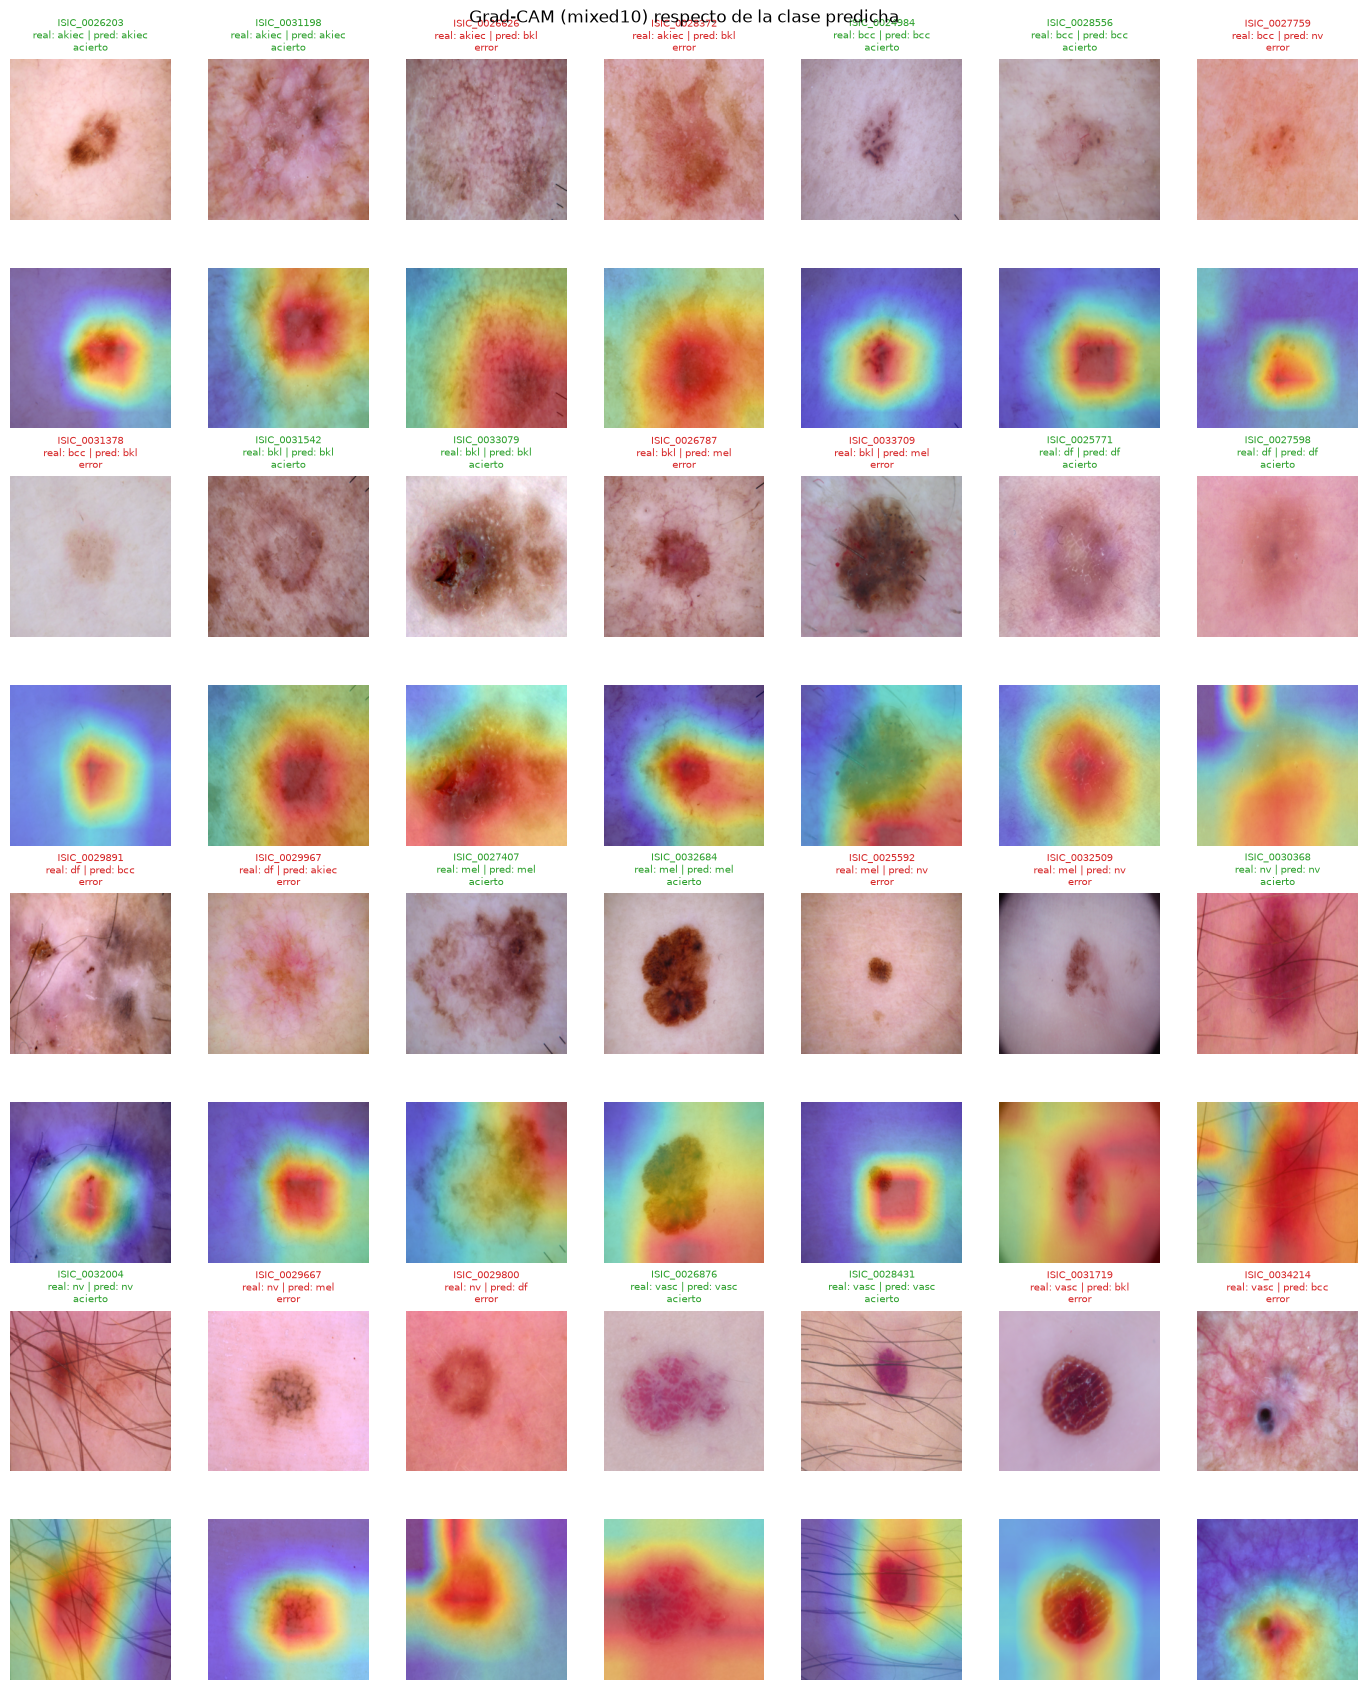

In [42]:
mapas = interpret.compute_saliency(cfg, MODELO, corrida_gradcam, muestra)
show(gradcam.plot_gradcam_grid(mapas, alpha=cfg_gradcam["alpha"], ncols=cfg_gradcam["ncols"]))